<a href="https://colab.research.google.com/github/EnesKok20/cepte-vet/blob/main/notebooks/06_deney_imgsz320.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

!pip -q install ultralytics
!nvidia-smi --query-gpu=name --format=csv

ANA = '/content/drive/MyDrive/436543_Enes_kok/cepte-veterinerlik'
!mkdir -p /content/data && cp "{ANA}/hazir/cattle_cls.zip" /content/data/
!cd /content/data && unzip -q -o cattle_cls.zip

Mounted at /content/drive
name
Tesla T4


In [5]:
from ultralytics import YOLO

model = YOLO('yolo11n-cls.pt')
model.train(
    data='/content/data/cattle_cls',
    epochs=30,
    imgsz=320,
    batch=32,
    patience=10,
    seed=42,
    project=f'{ANA}/runs',
    name='yolo11n_320',
    exist_ok=True,
)

New https://pypi.org/project/ultralytics/8.4.200 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.199 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/cattle_cls, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-cls.pt, momentum=0

ultralytics.utils.metrics.ClassifyMetrics object with attributes:

confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7d816a9de270>
curves: []
curves_results: []
fitness: 0.9770742356777191
keys: ['metrics/accuracy_top1', 'metrics/accuracy_top5']
results_dict: {'metrics/accuracy_top1': 0.9541484713554382, 'metrics/accuracy_top5': 1.0, 'fitness': 0.9770742356777191}
save_dir: PosixPath('/content/drive/MyDrive/436543_Enes_kok/cepte-veterinerlik/runs/yolo11n_320')
speed: {'preprocess': 1.0644532641938351, 'inference': 0.8559991048023856, 'loss': 0.0002151746686816665, 'postprocess': 0.0003475807899006543}
top1: 0.9541484713554382
top5: 1.0

In [3]:
import glob, os
from collections import Counter
from sklearn.metrics import classification_report, confusion_matrix

yollar = sorted(glob.glob('/content/data/cattle_cls/test/*/*'))
gercek = [os.path.basename(os.path.dirname(y)) for y in yollar]

def degerlendir(agirlik, boyut):
    m = YOLO(agirlik)
    tahmin = []
    for i in range(0, len(yollar), 64):
        for r in m.predict(yollar[i:i + 64], imgsz=boyut, verbose=False):
            tahmin.append(r.names[r.probs.top1])
    return tahmin

modeller = {
    'baseline_224': (f'{ANA}/runs/baseline_yolo11n/weights/best.pt', 224),
    'deney_320':    (f'{ANA}/runs/yolo11n_320/weights/best.pt', 320),
}

tahminler = {}
for ad, (agirlik, boyut) in modeller.items():
    tahminler[ad] = degerlendir(agirlik, boyut)
    print('=' * 15, ad, '=' * 15)
    print(classification_report(gercek, tahminler[ad], digits=3))
    print(confusion_matrix(gercek, tahminler[ad], labels=['healthy', 'lumpy']))
    kacan = [y for y, g, t in zip(yollar, gercek, tahminler[ad]) if g == 'lumpy' and t == 'healthy']
    print('Kaçırılan hastaların kaynağı:', Counter(os.path.basename(y).split('_')[0] for y in kacan))
    print()

=============== baseline_224 ===============
              precision    recall  f1-score   support

     healthy      0.921     0.935     0.928       276
       lumpy      0.899     0.880     0.890       183

    accuracy                          0.913       459
   macro avg      0.910     0.907     0.909       459
weighted avg      0.913     0.913     0.913       459

[[258  18]
 [ 22 161]]
Kaçırılan hastaların kaynağı: Counter({'kaggle': 18, 'mendeley': 4})

=============== deney_320 ===============
              precision    recall  f1-score   support

     healthy      0.936     0.949     0.942       276
       lumpy      0.922     0.902     0.912       183

    accuracy                          0.930       459
   macro avg      0.929     0.925     0.927       459
weighted avg      0.930     0.930     0.930       459

[[262  14]
 [ 18 165]]
Kaçırılan hastaların kaynağı: Counter({'kaggle': 15, 'mendeley': 3})



320 ile yeni yakalanan hasta: 7
320 ile yeni kaçırılan hasta: 3


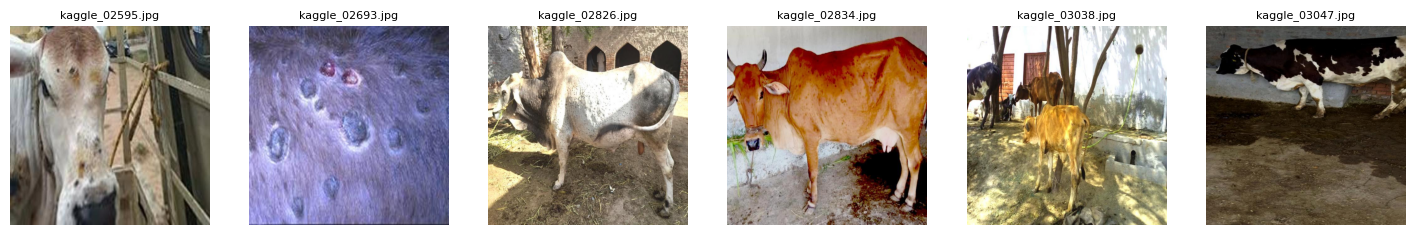

In [4]:
import matplotlib.pyplot as plt
from PIL import Image

b, d = tahminler['baseline_224'], tahminler['deney_320']
yeni_yakalanan = [y for y, g, tb, td in zip(yollar, gercek, b, d) if g == 'lumpy' and tb == 'healthy' and td == 'lumpy']
yeni_kacan     = [y for y, g, tb, td in zip(yollar, gercek, b, d) if g == 'lumpy' and tb == 'lumpy' and td == 'healthy']
print('320 ile yeni yakalanan hasta:', len(yeni_yakalanan))
print('320 ile yeni kaçırılan hasta:', len(yeni_kacan))

if yeni_yakalanan:
    fig, eks = plt.subplots(1, min(6, len(yeni_yakalanan)), figsize=(18, 3.5), squeeze=False)
    for ax, y in zip(eks[0], yeni_yakalanan):
        ax.imshow(Image.open(y).convert('RGB')); ax.set_title(os.path.basename(y), fontsize=8); ax.axis('off')
    plt.show()